### __4.2 StyTr²__

We then adopt StyTr², a transformer-based style transfer network. Instead of extracting features with a CNN, StyTr² splits the content and style images into patches and encodes them with two separate transformer encoders, so that long-range dependencies across the whole image can be captured. A transformer decoder then stylises the content sequence according to the style sequence, and a content-aware positional encoding (CAPE) keeps the positional information independent of the image resolution. In this project StyTr² serves as a comparison model. Our implementation follows the paper "StyTr²: Image Style Transfer with Transformers" (Deng et al., CVPR 2022) and its official code, re-written by our team in a single notebook. We adapt it to the project dataset, use a torchvision VGG-19 for the loss network, add mixed-precision training, checkpoint resuming and loss curve visualisation, and generate test results in the same format as IEContraAST.
https://github.com/diyiiyiii/StyTR-2

Requirements (Python=3.13.14):
torch==2.8.0+cu129
torchvision==0.23.0+cu129
numpy
pandas
Pillow
tqdm
matplotlib

##### __4.2.1 Model Definition__

Training this model requires specifying the paths to the datasets and the output directory. The pre-trained VGG-19 used by the loss network is downloaded automatically by torchvision. RTX 50-series GPUs (e.g. RTX 5060 Ti) need a PyTorch build with CUDA 12.8 or later.

In [13]:
import os
import time
import random
from pathlib import Path
from types import SimpleNamespace
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torchvision
from torchvision import transforms
from torchvision.utils import save_image
from tqdm import tqdm


DATA_ROOT = Path(r'D:\9444\Project\datasets')  # dataset directory path
CACHE_ROOT = Path(r'D:\9444\Project\datasets_cache_512')  # resized copies of the dataset (short side 512)
OUTPUT_ROOT = Path('StyTr2_result')  # output directory for checkpoints, logs, samples and test results
SEED = 42  # random seed for data splits and reference sampling

# auto-select the computing device
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
if DEVICE == 'cuda':
    torch.backends.cudnn.benchmark = True  # speed up convolutions for fixed input sizes
    torch.backends.cuda.matmul.allow_tf32 = True
    print('GPU:', torch.cuda.get_device_name(0))
print('device:', DEVICE)

# fix random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

GPU: NVIDIA GeForce RTX 5060 Ti
device: cuda


StyTr² treats style transfer as a sequence-to-sequence task on image patches. The patch embedding is an 8×8 convolution with stride 8, which turns an H×W image into an (H/8)×(W/8) grid of 512-dimensional tokens. The content-aware positional encoding (CAPE) average-pools the content embedding to a fixed 18×18 grid, applies a learnable 1×1 convolution and bilinearly interpolates it back to the token grid. Because the encoding is defined on a fixed grid and then resized, the relative positions of patches do not change with the image resolution, and the encoding depends on the image content. A standard 2-D sinusoidal positional encoding is also provided for comparison.

In [3]:
# patch embedding: 8x8 convolution with stride 8, B,3,H,W -> B,512,H/8,W/8
class PatchEmbed(nn.Module):
    def __init__(self, patch_size=8, in_chans=3, embed_dim=512):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        return self.proj(x)


# content-aware positional encoding (paper Section 3.1, Eq. 3)
class CAPE(nn.Module):
    def __init__(self, d_model=512, pool_size=18):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(pool_size)  # pool the content embedding to a fixed n x n grid
        self.proj = nn.Conv2d(d_model, d_model, kernel_size=1)  # learnable positional encoding function F_pos

    def forward(self, x):  # x: content embedding, B,C,h,w
        pos = self.proj(self.pool(x))  # B,C,18,18
        return F.interpolate(pos, size=x.shape[-2:], mode='bilinear', align_corners=False)  # resize to the token grid


# 2-D sinusoidal positional encoding (DETR style) with absolute coordinates, used for comparison only
def sine_positional_encoding(x, temperature=10000):
    b, c, h, w = x.shape
    npf = c // 2
    y_embed = torch.arange(1, h + 1, device=x.device, dtype=torch.float32)[:, None].expand(h, w)
    x_embed = torch.arange(1, w + 1, device=x.device, dtype=torch.float32)[None, :].expand(h, w)
    dim_t = torch.arange(npf, device=x.device, dtype=torch.float32)
    dim_t = temperature ** (2 * (dim_t // 2) / npf)
    pos_x = x_embed[..., None] / dim_t
    pos_y = y_embed[..., None] / dim_t
    pos_x = torch.stack((pos_x[..., 0::2].sin(), pos_x[..., 1::2].cos()), dim=3).flatten(2)
    pos_y = torch.stack((pos_y[..., 0::2].sin(), pos_y[..., 1::2].cos()), dim=3).flatten(2)
    pos = torch.cat((pos_y, pos_x), dim=2).permute(2, 0, 1)  # C,h,w
    return pos.unsqueeze(0).expand(b, -1, -1, -1).to(x.dtype)

The transformer follows the official implementation (DETR style, post-norm). Each encoder layer contains multi-head self-attention and a feed-forward network, with the positional encoding added to the queries and keys. The content encoder uses CAPE, while the style encoder uses no positional encoding because the spatial layout of the style image should not be kept. Each decoder layer contains two attention blocks in which the queries come from the content sequence and the keys and values come from the style sequence, followed by a feed-forward network. All tokens are decoded at once rather than auto-regressively.

In [4]:
# add the positional encoding if it exists
def with_pos(x, pos):
    return x if pos is None else x + pos


# transformer encoder layer: self-attention + feed-forward network, post-norm
class EncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_ff)
        self.linear2 = nn.Linear(dim_ff, d_model)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop, self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, src, pos=None):
        q = k = with_pos(src, pos)  # positional encoding is added to queries and keys only
        src = self.norm1(src + self.drop1(self.self_attn(q, k, src, need_weights=False)[0]))
        ff = self.linear2(self.drop(F.relu(self.linear1(src))))
        return self.norm2(src + self.drop2(ff))


# transformer decoder layer: two attention blocks (Q = content, K/V = style) + feed-forward network (paper Eq. 8)
class DecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.attn1 = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.attn2 = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_ff)
        self.linear2 = nn.Linear(dim_ff, d_model)
        self.norm1, self.norm2, self.norm3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.drop1, self.drop2, self.drop3 = nn.Dropout(dropout), nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, tgt, memory, query_pos=None, pos=None):
        # tgt: content sequence (queries); memory: style sequence (keys / values)
        k = with_pos(memory, pos)
        tgt = self.norm1(tgt + self.drop1(self.attn1(with_pos(tgt, query_pos), k, memory, need_weights=False)[0]))
        tgt = self.norm2(tgt + self.drop2(self.attn2(with_pos(tgt, query_pos), k, memory, need_weights=False)[0]))
        ff = self.linear2(self.drop(F.relu(self.linear1(tgt))))
        return self.norm3(tgt + self.drop3(ff))


# content encoder + style encoder + decoder
class StyleTransformer(nn.Module):
    def __init__(self, d_model=512, nhead=8, n_enc=3, n_dec=3, dim_ff=2048, dropout=0.1):
        super().__init__()
        self.encoder_c = nn.ModuleList([EncoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_enc)])
        self.encoder_s = nn.ModuleList([EncoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_enc)])
        self.decoder = nn.ModuleList([DecoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_dec)])
        self.decoder_norm = nn.LayerNorm(d_model)
        for p in self.parameters():  # Xavier initialisation, as in the official code
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, style, content, pos_c=None):
        # inputs are B,C,h,w; the output has the same h,w as the content (non-square inputs supported)
        b, c, h, w = content.shape
        flat = lambda t: None if t is None else t.flatten(2).transpose(1, 2)  # B,C,h,w -> B,hw,C
        s, x, pc = flat(style), flat(content), flat(pos_c)
        for layer in self.encoder_s:
            s = layer(s, pos=None)  # style encoder: no positional encoding
        for layer in self.encoder_c:
            x = layer(x, pos=pc)  # content encoder: with CAPE
        for layer in self.decoder:
            x = layer(x, s, query_pos=pc, pos=None)
        x = self.decoder_norm(x)
        return x.transpose(1, 2).reshape(b, c, h, w)

Instead of reshaping the output tokens directly into pixels, a CNN decoder upsamples the transformer output by a factor of 2 three times (3×3 convolution + ReLU + nearest upsampling with reflection padding) to reconstruct the stylised image.

A frozen ImageNet-pretrained VGG-19 provides features at relu1_1 to relu5_1 for the loss computation. Four loss terms are defined as follows: content loss measures the differences between the mean-variance normalised features of the generated and content images at relu4_1 and relu5_1; style loss compares the channel-wise means and standard deviations of the features of the generated and style images over all five layers; and pixel-level and feature-level identity losses encourage accurate reconstruction when the same image is used as both the content and the style input.

In [5]:
# 3x3 convolution with reflection padding (+ ReLU)
def conv_block(cin, cout, relu=True):
    layers = [nn.ReflectionPad2d(1), nn.Conv2d(cin, cout, 3)]
    if relu:
        layers.append(nn.ReLU(inplace=True))
    return layers


# CNN decoder: upsamples the transformer output 3 times (x8 in total)
def build_cnn_decoder():
    up = lambda: nn.Upsample(scale_factor=2, mode='nearest')
    return nn.Sequential(
        *conv_block(512, 256), up(),
        *conv_block(256, 256), *conv_block(256, 256), *conv_block(256, 256),
        *conv_block(256, 128), up(),
        *conv_block(128, 128), *conv_block(128, 64), up(),
        *conv_block(64, 64), *conv_block(64, 3, relu=False),
    )


# frozen VGG-19 loss network, returns relu1_1 ... relu5_1 features
class VGGFeatures(nn.Module):
    LAYER_ENDS = [2, 7, 12, 21, 30]  # positions after relu1_1 ... relu5_1 in torchvision vgg19.features

    def __init__(self):
        super().__init__()
        vgg = torchvision.models.vgg19(weights=torchvision.models.VGG19_Weights.IMAGENET1K_V1).features
        self.slices = nn.ModuleList()
        start = 0
        for end in self.LAYER_ENDS:
            self.slices.append(nn.Sequential(*[vgg[i] for i in range(start, end)]))
            start = end
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        for p in self.parameters():
            p.requires_grad_(False)
        self.eval()

    def train(self, mode=True):  # always stay in evaluation mode
        return super().train(False)

    def forward(self, x):  # x in [0, 1]
        x = (x - self.mean) / self.std  # ImageNet normalisation
        feats = []
        for s in self.slices:
            x = s(x)
            feats.append(x)
        return feats


# calculate the mean and standard deviation of the feature map across each channel, used to measure style
def calc_mean_std(feat, eps=1e-5):
    b, c = feat.shape[:2]
    var = feat.reshape(b, c, -1).var(dim=2) + eps
    return feat.reshape(b, c, -1).mean(dim=2).view(b, c, 1, 1), var.sqrt().view(b, c, 1, 1)


# normalise each channel to zero mean and unit variance
def mean_variance_norm(feat):
    mean, std = calc_mean_std(feat)
    return (feat - mean) / std


# content loss (paper Eq. 9): normalised features at relu4_1 and relu5_1
def content_loss(out_feats, content_feats):
    return sum(F.mse_loss(mean_variance_norm(out_feats[i].float()), mean_variance_norm(content_feats[i].float()))
               for i in (-2, -1))


# style loss (paper Eq. 10): channel-wise mean and std over the five layers
def style_loss(out_feats, style_feats):
    loss = 0.0
    for o, s in zip(out_feats, style_feats):
        om, os_ = calc_mean_std(o.float())
        sm, ss = calc_mean_std(s.float())
        loss = loss + F.mse_loss(om, sm) + F.mse_loss(os_, ss)
    return loss

The full StyTr² model combines the patch embedding, CAPE, the style transformer and the CNN decoder. During training, three forward passes are made per batch: content + style for the stylised output, and content + content and style + style for the identity losses. The total loss is L = 10·Lc + 7·Ls + 50·Lid1 + 1·Lid2, using the weights reported in the paper.

In [6]:
# model hyper-parameters (same as the paper)
MODEL_CFG = dict(patch_size=8, d_model=512, nhead=8, num_enc_layers=3, num_dec_layers=3,
                 dim_feedforward=2048, dropout=0.1, cape_pool_size=18,
                 pos_encoding='cape')  # 'cape' | 'sine' | 'none'


class StyTr2(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg['d_model']
        self.patch = cfg['patch_size']
        self.embed = PatchEmbed(cfg['patch_size'], 3, d)
        self.transformer = StyleTransformer(d, cfg['nhead'], cfg['num_enc_layers'], cfg['num_dec_layers'],
                                            cfg['dim_feedforward'], cfg['dropout'])
        self.decoder = build_cnn_decoder()
        self.pos_type = cfg['pos_encoding']
        self.cape = CAPE(d, cfg['cape_pool_size']) if self.pos_type == 'cape' else None

    def positional_encoding(self, content_emb):
        if self.pos_type == 'cape':
            return self.cape(content_emb)
        if self.pos_type == 'sine':
            return sine_positional_encoding(content_emb)
        return None

    def forward(self, content, style):
        # input sizes must be multiples of 8; content and style may have different sizes
        c_emb, s_emb = self.embed(content), self.embed(style)
        pos_c = self.positional_encoding(c_emb)
        hs = self.transformer(s_emb, c_emb, pos_c)
        return self.decoder(hs)


# forward passes and the four loss terms
def compute_losses(model, vgg, content, style, args):
    Ics = model(content, style)  # stylised output
    Icc = model(content, content)  # identity: content + content
    Iss = model(style, style)  # identity: style + style

    f_c, f_s = vgg(content), vgg(style)
    f_cs, f_cc, f_ss = vgg(Ics), vgg(Icc), vgg(Iss)

    l_c = content_loss(f_cs, f_c)
    l_s = style_loss(f_cs, f_s)
    l_id1 = F.mse_loss(Icc.float(), content.float()) + F.mse_loss(Iss.float(), style.float())  # pixel level
    l_id2 = sum(F.mse_loss(a.float(), b.float()) + F.mse_loss(x.float(), y.float())  # feature level
                for a, b, x, y in zip(f_cc, f_c, f_ss, f_s))
    total = args.lambda_c * l_c + args.lambda_s * l_s + args.lambda_id1 * l_id1 + args.lambda_id2 * l_id2
    return dict(total=total, content=l_c, style=l_s, identity_pixel=l_id1, identity_feature=l_id2), Ics


n_params = sum(p.numel() for p in StyTr2(MODEL_CFG).parameters())
print(f'StyTr2 trainable parameters: {n_params / 1e6:.2f} M')

StyTr2 trainable parameters: 35.39 M


The training data are prepared as follows. A validation set is held out from the training folders (5% of the content images and 14 paintings per style category) and is used to select the best checkpoint. Because the WikiArt paintings are large, every image is resized once so that its short side is 512 pixels and cached to disk; during training, 256×256 patches are randomly cropped from the cached images. Infinite iterators are used so that the content and style sets, which have different sizes, are sampled independently.

In [7]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.jfif'}


# recursively collect image paths, filter formats and hidden files
def list_images(root):
    root = Path(root)
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
                  and not any(part.startswith('.') for part in p.relative_to(root).parts))


# hold out a validation set: random content images, and a fixed number of paintings per style category
def split_train_val(content_paths, style_paths, val_content_ratio, val_style_per_class, seed):
    rng = random.Random(seed)
    shuffled = list(content_paths)
    rng.shuffle(shuffled)
    n_val = max(1, int(len(shuffled) * val_content_ratio))
    content_val, content_train = sorted(shuffled[:n_val]), sorted(shuffled[n_val:])

    style_train, style_val = [], []
    for cls in sorted({p.parent.name for p in style_paths}):  # stratified by style category
        imgs = sorted(p for p in style_paths if p.parent.name == cls)
        rng.shuffle(imgs)
        k = min(val_style_per_class, max(1, len(imgs) // 10))
        style_val += imgs[:k]
        style_train += imgs[k:]
    return content_train, content_val, sorted(style_train), sorted(style_val)


# resize every image once (short side = short_side) and save it to the cache folder
def cache_images(paths, src_root, cache_root, short_side=512):
    src_root, cache_root = Path(src_root), Path(cache_root)

    def resize_one(src):
        dst = cache_root / src_root.name / src.relative_to(src_root).with_suffix('.jpg')
        if not dst.exists():
            with Image.open(src) as img:
                img.draft('RGB', (short_side, short_side))  # fast JPEG down-scaling while decoding
                img = img.convert('RGB')
                scale = short_side / min(img.size)
                img = img.resize((max(1, round(img.size[0] * scale)), max(1, round(img.size[1] * scale))),
                                 Image.BICUBIC)
                dst.parent.mkdir(parents=True, exist_ok=True)
                img.save(dst, quality=95)
        return dst

    with ThreadPoolExecutor(max_workers=8) as pool:
        return list(tqdm(pool.map(resize_one, paths), total=len(paths), desc=f'Caching {src_root.name}'))


# dataset that reads images from a list of paths
class ImageListDataset(data.Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            return self.transform(img.convert('RGB'))

    def __len__(self):
        return len(self.paths)


# generator: loops over a DataLoader forever
def infinite(loader):
    while True:
        for batch in loader:
            yield batch

##### __4.2.2 Model Training__

The whole training process consists of 40,000 iterations with a batch size of 8. In each iteration, batches of content and style images are sampled from the training sets and randomly cropped to 256×256. The model produces the stylised images and the two identity reconstructions, the frozen VGG-19 extracts their features, and the four losses are weighted and summed to form the total loss. The model is optimised with Adam; following the official code, the learning rate is warmed up during the first 10,000 iterations (lr·0.1·(1 + 3t/T)) and then decays inversely with the iteration count. Mixed precision (bf16 when supported) is used to save memory, and the gradient norm is clipped at 1.0. Every 1,000 iterations the validation loss is computed and the checkpoint with the lowest validation loss is kept; the latest checkpoint is saved every 2,000 iterations so that training can be resumed.

In [ ]:
# learning rate: warm-up followed by inverse decay (same form as the official code)
def get_lr(it, args):
    if it < args.warmup_iters:
        return args.lr * 0.1 * (1.0 + 3.0 * it / max(1, args.warmup_iters))
    return args.lr * 0.4 / (1.0 + args.lr_decay * (it - args.warmup_iters))


# training function
def run_training(**options):
    # default options; run_training(**options) overrides them
    args = SimpleNamespace(
        content_dir=str(DATA_ROOT / 'content_train'), style_dir=str(DATA_ROOT / 'style_train'),
        cache_dir=str(CACHE_ROOT), save_dir=str(OUTPUT_ROOT / 'experiments'),
        sample_path=str(OUTPUT_ROOT / 'samples'), log_dir=str(OUTPUT_ROOT / 'logs'),
        cache_short_side=512, crop_size=256, val_content_ratio=0.05, val_style_per_class=14,
        lr=5e-4, warmup_iters=10000, lr_decay=1e-5, max_iter=40000, batch_size=8,
        lambda_c=10.0, lambda_s=7.0, lambda_id1=50.0, lambda_id2=1.0,
        grad_clip=1.0, use_amp=True, n_threads=0 if os.name == 'nt' else 4,
        print_freq=100, val_freq=1000, sample_freq=2000, save_model_interval=2000,
        resume=True, seed=SEED, device=DEVICE)
    unknown = set(options) - set(vars(args))
    if unknown:  # unknown option check
        raise ValueError(f'Unknown options: {unknown}')
    for key, value in options.items():  # override with options
        setattr(args, key, value)

    device = torch.device(args.device)
    save_dir, sample_dir, log_dir = Path(args.save_dir), Path(args.sample_path), Path(args.log_dir)
    for d in (save_dir, sample_dir, log_dir):
        d.mkdir(parents=True, exist_ok=True)

    # data: train / validation split, cache, DataLoaders
    content_train, content_val, style_train, style_val = split_train_val(
        list_images(args.content_dir), list_images(args.style_dir),
        args.val_content_ratio, args.val_style_per_class, args.seed)
    print(f'content train/val = {len(content_train)}/{len(content_val)}; '
          f'style train/val = {len(style_train)}/{len(style_val)}', flush=True)
    c_train = cache_images(content_train, args.content_dir, args.cache_dir, args.cache_short_side)
    s_train = cache_images(style_train, args.style_dir, args.cache_dir, args.cache_short_side)
    c_val = cache_images(content_val, args.content_dir, args.cache_dir, args.cache_short_side)
    s_val = cache_images(style_val, args.style_dir, args.cache_dir, args.cache_short_side)

    train_tf = transforms.Compose([transforms.Resize(args.cache_short_side),
                                   transforms.RandomCrop(args.crop_size), transforms.ToTensor()])
    eval_tf = transforms.Compose([transforms.Resize(args.crop_size),
                                  transforms.CenterCrop(args.crop_size), transforms.ToTensor()])
    make_loader = lambda paths: data.DataLoader(
        ImageListDataset(paths, train_tf), batch_size=args.batch_size, shuffle=True, drop_last=True,
        num_workers=args.n_threads, pin_memory=(device.type == 'cuda'), persistent_workers=args.n_threads > 0)
    content_iter, style_iter = infinite(make_loader(c_train)), infinite(make_loader(s_train))

    # fixed validation pairs
    val_rng = random.Random(args.seed)
    n_val = min(32, len(c_val), len(s_val))
    load = lambda paths: torch.stack([eval_tf(Image.open(p).convert('RGB')) for p in paths])
    val_content, val_style = load(val_rng.sample(c_val, n_val)), load(val_rng.sample(s_val, n_val))

    # model, frozen VGG loss network, optimizer, mixed precision
    model = StyTr2(MODEL_CFG).to(device)
    vgg = VGGFeatures().to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=args.lr)
    use_amp = args.use_amp and device.type == 'cuda'
    amp_dtype = torch.bfloat16 if (use_amp and torch.cuda.is_bf16_supported()) else torch.float16
    scaler = torch.amp.GradScaler('cuda', enabled=(use_amp and amp_dtype == torch.float16))
    autocast = lambda: torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp)

    # resume from the latest checkpoint if it exists
    latest, best = save_dir / 'checkpoint_latest.pt', save_dir / 'checkpoint_best.pt'
    start_iter, history, best_val = 0, [], float('inf')
    if args.resume and latest.is_file():
        ckpt = torch.load(latest, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scaler.load_state_dict(ckpt['scaler'])
        start_iter, history, best_val = ckpt['iter'], ckpt['history'], ckpt['best_val']
        print(f'Resumed from iteration {start_iter}', flush=True)

    def save_checkpoint(path, it):
        temporary = path.with_suffix('.tmp')
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scaler=scaler.state_dict(),
                        iter=it, history=history, best_val=best_val, model_cfg=MODEL_CFG,
                        config={k: str(v) for k, v in vars(args).items()}), temporary)
        os.replace(temporary, path)

    @torch.no_grad()
    def validate():
        model.eval()
        sums = {}
        for i in range(0, n_val, args.batch_size):
            c, s = val_content[i:i + args.batch_size].to(device), val_style[i:i + args.batch_size].to(device)
            with autocast():
                losses, _ = compute_losses(model, vgg, c, s, args)
            for k, v in losses.items():
                sums[k] = sums.get(k, 0.0) + v.item() * len(c)
        model.train()
        return {k: v / n_val for k, v in sums.items()}

    @torch.no_grad()
    def save_samples(it, n=6):
        model.eval()
        c, s = val_content[:n].to(device), val_style[:n].to(device)
        with autocast():
            out = model(c, s).float().clamp(0, 1)
        model.train()
        output = torch.cat([s, c, out], 2)  # concatenate style / content / result vertically
        save_image(output, sample_dir / f'output{it}.jpg', nrow=n)

    print(f'device={device}; iterations={start_iter}..{args.max_iter}; batch={args.batch_size}; '
          f'crop={args.crop_size}; mixed precision={use_amp} ({amp_dtype})', flush=True)
    print(f'weights: content={args.lambda_c}, style={args.lambda_s}, '
          f'identity={args.lambda_id1}/{args.lambda_id2}', flush=True)

    # iterative training
    model.train()
    running = {}
    for i in tqdm(range(start_iter, args.max_iter), initial=start_iter, total=args.max_iter):
        lr = get_lr(i, args)  # adjust learning rate
        for group in optimizer.param_groups:
            group['lr'] = lr
        content_images = next(content_iter).to(device, non_blocking=True)  # fetch training data
        style_images = next(style_iter).to(device, non_blocking=True)

        with autocast():  # forward pass and losses
            losses, Ics = compute_losses(model, vgg, content_images, style_images, args)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(losses['total']).backward()
        scaler.unscale_(optimizer)  # restore the gradient scale before clipping
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), args.grad_clip if args.grad_clip is not None else float('inf'))
        scaler.step(optimizer)
        scaler.update()

        losses['grad_norm'] = grad_norm.detach()
        losses['output_std'] = Ics.detach().float().std(dim=(2, 3)).mean()  # spatial std; ~0 means a flat image
        for k, v in losses.items():
            running[k] = running.get(k, 0.0) + v.item()
        step = i + 1

        # log the average losses periodically
        if step % args.print_freq == 0:
            avg = {k: v / args.print_freq for k, v in running.items()}
            history.append(dict(iter=step, split='train', lr=lr, **avg))
            running = {}
            if step % (args.print_freq * 20) == 0:
                print(f'iter {step}: ' + ', '.join(f'{k}={v:.4f}' for k, v in avg.items()), flush=True)

        # validation and best checkpoint
        if step % args.val_freq == 0:
            val = validate()
            history.append(dict(iter=step, split='val', lr=lr, **val))
            if val['total'] < best_val:
                best_val = val['total']
                save_checkpoint(best, step)
            print(f'iter {step}: validation total={val["total"]:.4f} (best {best_val:.4f})', flush=True)

        # save samples periodically
        if step == 1 or step % args.sample_freq == 0:
            save_samples(step)

        # save the latest checkpoint and the loss history
        if step % args.save_model_interval == 0 or step == args.max_iter:
            save_checkpoint(latest, step)
            pd.DataFrame(history).to_csv(log_dir / 'history.csv', index=False)

    pd.DataFrame(history).to_csv(log_dir / 'history.csv', index=False)
    print(f'Training finished. Best validation loss: {best_val:.4f}', flush=True)


# check data
for split in ['content_train', 'content_test', 'style_train', 'style_test']:
    print(split, len(list_images(DATA_ROOT / split)))

# start training (resumes automatically if a checkpoint already exists)
MAX_ITER = 40000
run_training(
    content_dir=str(DATA_ROOT / 'content_train'),
    style_dir=str(DATA_ROOT / 'style_train'),
    max_iter=MAX_ITER,
    batch_size=8,
    device=DEVICE,
    save_dir=str(OUTPUT_ROOT / 'experiments'),
    sample_path=str(OUTPUT_ROOT / 'samples'),
    log_dir=str(OUTPUT_ROOT / 'logs'),
)

The average loss values recorded during training are plotted below. The left figure shows the total loss on the training set and the validation set, and the right figure shows the weighted contribution of each loss term, which is used to check the balance between content preservation, style transfer and identity reconstruction.

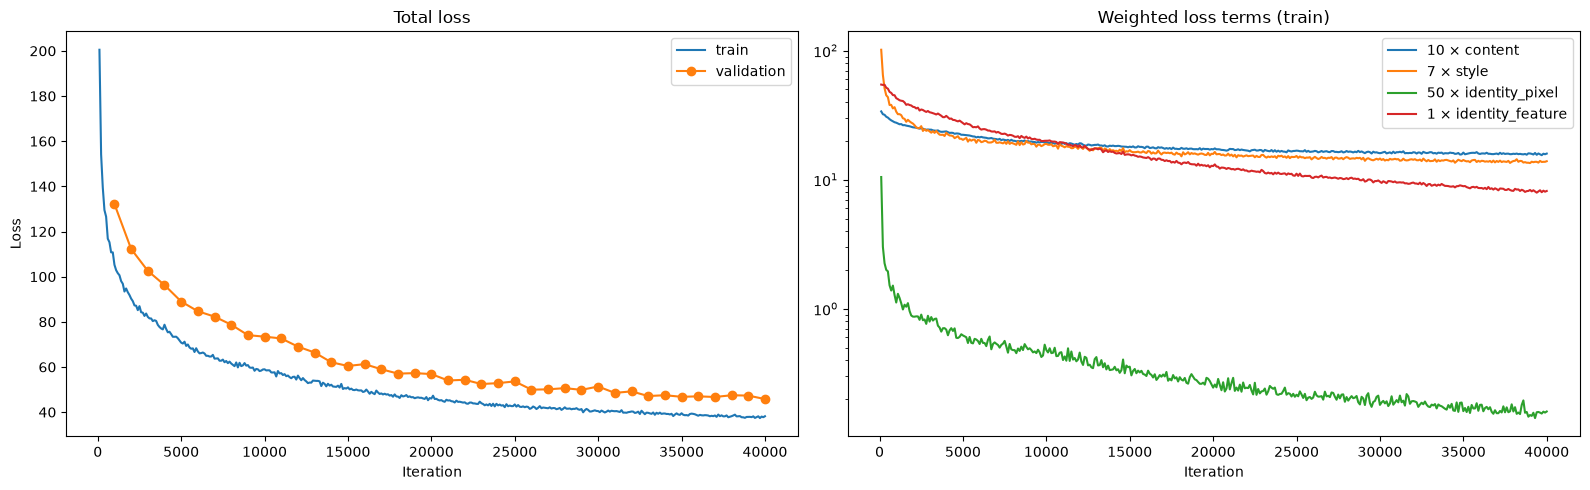

In [11]:
LOG_DIR = Path('outputs/stytr2_cape')
history = pd.read_csv(LOG_DIR / 'history.csv')
history = history.rename(columns={'id1': 'identity_pixel', 'id2': 'identity_feature'})
train_log, val_log = history[history.split == 'train'], history[history.split == 'val']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# total loss
axes[0].plot(train_log['iter'], train_log['total'], label='train')
axes[0].plot(val_log['iter'], val_log['total'], 'o-', label='validation')
axes[0].set_title('Total loss')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Loss')
axes[0].legend()

# weighted loss terms
weights = {'content': 10.0, 'style': 7.0, 'identity_pixel': 50.0, 'identity_feature': 1.0}
for name, w in weights.items():
    if name in train_log:
        axes[1].plot(train_log['iter'], w * train_log[name], label=f'{w:g} × {name}')
axes[1].set_yscale('log')
axes[1].set_title('Weighted loss terms (train)')
axes[1].set_xlabel('Iteration')
axes[1].legend()

plt.tight_layout()
plt.show()

##### __4.2.3 Model Testing__

During testing, the trained weights are loaded and the model is set to evaluation mode. The model then processes all 400 images in the content test set. For each content image, one reference image is randomly selected from each style folder, and both are resized (short side 256, long side at most 512) and padded to a multiple of 8, the same preprocessing as for IEContraAST. The content and reference images are split into patches and encoded by the two transformer encoders, fused by the transformer decoder and passed through the CNN decoder to produce the stylised output. Each output is saved alongside its corresponding content and reference images for visual comparison and quantitative evaluation. This process produces 2,800 image triplets across seven style categories.

In [15]:
# image collection function, returns image paths
def images(root):
    root = Path(root)
    if root.is_file() and root.suffix.lower() in IMAGE_EXTENSIONS:  # single file
        return [root]
    return list_images(root)  # directory


# image preprocessing function
def prepare(path, size, device):
    # read image and convert to RGB
    with Image.open(path) as source:
        image = source.convert('RGB')
    # keep aspect ratio: short side to 256, long side not exceeding 512
    if size:
        scale = min(size / min(image.size), 512 / max(image.size))
        image = image.resize(tuple(max(32, round(s * scale)) for s in image.size), Image.Resampling.LANCZOS)
    # convert to tensor
    tensor = transforms.ToTensor()(image).unsqueeze(0).to(device)
    # reflect pad to a multiple of 8 (patch size)
    height, width = tensor.shape[-2:]
    padded = F.pad(tensor, (0, (-width) % 8, 0, (-height) % 8), mode='reflect')
    return tensor, padded


# testing function
def run_testing(**options):
    # default options; run_testing(**options) overrides them
    args = SimpleNamespace(
        content=str(DATA_ROOT / 'content_test'), style_dir=str(DATA_ROOT / 'style_test'),
        checkpoint=str(OUTPUT_ROOT / 'experiments' / 'checkpoint_best.pt'),
        output=str(OUTPUT_ROOT / 'test_results'),
        size=256, max_images=0, use_amp=True, seed=SEED, device=DEVICE)
    unknown = set(options) - set(vars(args))
    if unknown:  # unknown option check
        raise ValueError(f'Unknown options: {unknown}')
    for key, value in options.items():  # override with options
        setattr(args, key, value)

    # content images, max_images == 0 means all
    contents = images(args.content)
    if not contents:
        raise ValueError(f'No content images: {args.content}')
    if args.max_images:
        contents = contents[:args.max_images]

    # reference candidates for each style folder
    root = Path(args.style_dir)
    folders = sorted(p for p in root.iterdir() if p.is_dir() and not p.name.startswith('.'))
    references = [(folder.name, images(folder)) for folder in folders if images(folder)]
    if not references:
        raise ValueError(f'No reference images: {args.style_dir}')

    # load trained weights
    device = torch.device(args.device)
    if not Path(args.checkpoint).is_file():
        raise FileNotFoundError(f'Train the model first; checkpoint not found: {args.checkpoint}')
    weights = torch.load(args.checkpoint, map_location='cpu', weights_only=False)
    model = StyTr2(MODEL_CFG)
    model.load_state_dict(weights['model'])
    model.eval().to(device)  # switch to inference mode and move to device
    print(f"Loaded trained checkpoint: iteration {weights['iter']}")

    use_amp = args.use_amp and device.type == 'cuda'
    amp_dtype = torch.bfloat16 if (use_amp and torch.cuda.is_bf16_supported()) else torch.float16
    rng = random.Random(args.seed)  # fixed seed for reference sampling
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)

    with torch.inference_mode():
        counter = 1  # image counter
        # iterate over all content images
        for path in tqdm(contents, desc='Testing'):
            content, padded_content = prepare(path, args.size, device)  # preprocess content image
            # iterate over all style folders
            for name, candidates in references:
                reference_path = rng.choice(candidates)  # resample for each content-style pair
                reference, padded_reference = prepare(reference_path, args.size, device)  # preprocess style image
                with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                    result = model(padded_content, padded_reference).float()  # stylise
                result = result[..., :content.shape[-2], :content.shape[-1]]  # remove the padding
                if not torch.isfinite(result).all():
                    raise FloatingPointError('Non-finite model output')

                # create subfolder for each style
                style_dir = output / name
                style_dir.mkdir(parents=True, exist_ok=True)
                # save the corresponding content, reference and result images
                save_image(content, style_dir / f'{counter}_content.png')
                save_image(result.clamp(0, 1), style_dir / f'{counter}_result.png')
                save_image(reference, style_dir / f'{counter}_reference.png')

            counter += 1  # increment counter
    print(f'Inference complete! All results saved to: {output}', flush=True)


# start testing
run_testing(
    checkpoint='outputs/stytr2_cape/ckpt_best.pt',
    content=str(DATA_ROOT / 'content_test'),
    style_dir=str(DATA_ROOT / 'style_test'),
    output=str(OUTPUT_ROOT / 'test_results'),
    max_images=0,  # process all 400 images
    device=DEVICE,
)

Loaded trained checkpoint: iteration 40000


Testing: 100%|██████████| 400/400 [04:47<00:00,  1.39it/s]

Inference complete! All results saved to: StyTr2_result\test_results


From the test results, we randomly select one sample per style (style image / content image / result image), uniformly resize them to 256 × 256, and display them for visual comparison.

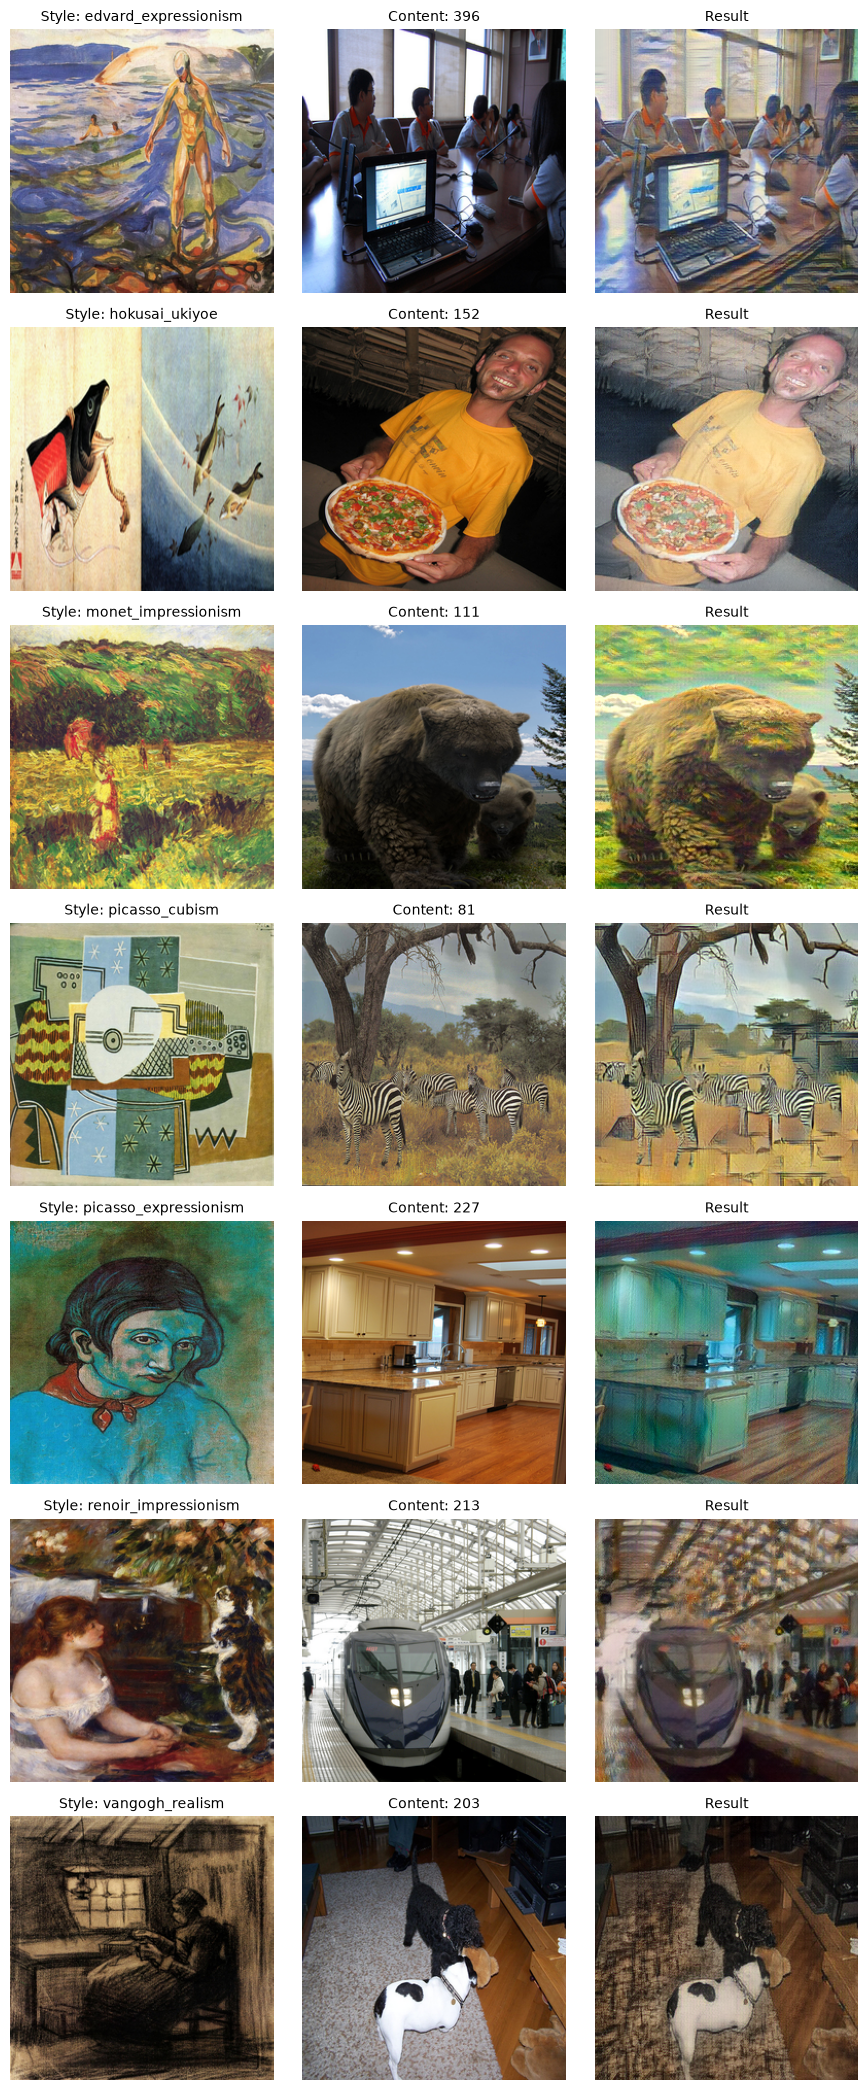

In [16]:
RESULT_DIR = OUTPUT_ROOT / 'test_results'


def load_and_resize(path):
    img = Image.open(path).convert('RGB')
    return img.resize((256, 256), Image.Resampling.LANCZOS)


# get all style folders
style_dirs = sorted([d for d in RESULT_DIR.iterdir() if d.is_dir()])

# one row per style, 3 fixed columns
fig, axes = plt.subplots(len(style_dirs), 3, figsize=(9, 3 * len(style_dirs)))
if len(style_dirs) == 1:
    axes = [axes]

for row, style_dir in enumerate(style_dirs):
    style_name = style_dir.name

    # randomly pick one existing result in this style folder
    existing_results = list(style_dir.glob('*_result.png'))
    if not existing_results:
        continue
    selected_result = random.choice(existing_results)
    target_idx = selected_result.name.split('_')[0]  # extract the index

    # paths of the corresponding reference and content images
    ref_path = style_dir / f'{target_idx}_reference.png'
    content_path = style_dir / f'{target_idx}_content.png'
    if not (ref_path.is_file() and content_path.is_file()):
        print(f'Missing associated images for index {target_idx}, skip {style_name}')
        continue

    for col, (path, title) in enumerate([(ref_path, f'Style: {style_name}'),
                                         (content_path, f'Content: {target_idx}'),
                                         (selected_result, 'Result')]):
        axes[row][col].imshow(load_and_resize(path))
        axes[row][col].set_title(title, fontsize=10)
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()